In [44]:
from sklearn.datasets import make_regression
import matplotlib.pyplot as plt
import numpy as np
from sklearn.model_selection import cross_val_score

In [45]:
X,y = make_regression(n_samples=100, n_features=1, n_informative=1, n_targets=1, noise=20)

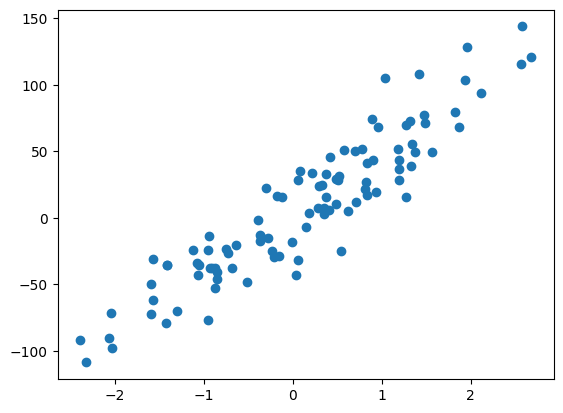

In [46]:
plt.scatter(X, y)

In [87]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=2)

In [88]:
from sklearn.linear_model import LinearRegression

In [89]:
lr = LinearRegression()

In [95]:
lr.fit(X_train,y_train)
print(lr.coef_)
print(lr.intercept_)

[44.02389728]
3.675064303373592


In [101]:
y_pred = lr.predict(X_test)
from sklearn.metrics import r2_score
r2_score(y_test, y_pred)

0.8249599746183586

In [102]:
class GDRegressor:

    def __init__(self, learning_rate, epochs):
        self.m = 100
        self.b = -120
        self.lr = learning_rate
        self.epochs = epochs

    def fit(self, X, y):
        #calculate the b using GD
        for i in range(self.epochs):
            loss_slope_b = -2 * np.sum(y - self.m*X.ravel()-self.b)
            loss_slope_m = -2 * np.sum((y - self.m * X.ravel() - self.b)*X.ravel())
            self.b = self.b - (self.lr * loss_slope_b)
            self.m = self.m - (self.lr * loss_slope_m)
            #print(loss_slope_b, self.b)
        print(self.m ,self.b)

    def predict(self, X):
        return self.m * X + self.b

In [106]:
gd = GDRegressor(0.001,50)

In [107]:
gd.fit(X_train, y_train)

44.06631446550106 3.6019580124317576


In [109]:
y_pred = gd.predict(X_test)
from sklearn.metrics import r2_score
r2_score(y_test, y_pred)

0.8251106509788225